# Phase 6 : comportements transactionnels (Q2, Q6)

Ce notebook décrit les comportements des clients : montants, canaux de paiement, évolution dans le temps, lieux, catégories de commerçants, erreurs, puis comportements de chaque profil de la phase 5. Il part de la table d'analyse (P4-10). Les fonctions de comparaison sont dans `src/comparisons.py`. Chaque étape est expliquée dans `docs/`.

Avec 13 millions de lignes, presque tout écart est « significatif ». Chaque comparaison chiffrée donne donc aussi la taille de l'écart (P6-06).

## Chargement des données

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.load_data import load_clean_table
from src.charte import (
    apply_style, save_figure, CATEGORIES, BLUE, ORANGE, TEXT_SECONDARY, THOUSANDS, DECIMALS, sequential_cmap,
)
from src.comparisons import rate_table, chi2_test

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

colonnes = ["id", "date", "client_id", "card_id", "amount", "use_chip", "is_online", "is_foreign",
            "merchant_state_clean", "merchant_country", "mcc", "mcc_family", "has_error", "has_auth_error",
            "err_insufficient_balance", "err_technical_glitch", "err_bad_pin", "err_bad_cvv",
            "err_bad_card_number", "err_bad_expiration", "err_bad_zipcode", "year", "month", "weekday",
            "hour", "is_night", "is_weekend", "is_round_amount", "is_negative_amount", "is_zero_amount",
            "card_auth_errors_24h"]
df = load_clean_table("analysis", columns=colonnes)
df_mcc = load_clean_table("mcc")
achats = df["amount"] > 0
df["achat"] = df["amount"].where(achats, 0.0)
JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
CANAUX = {"Swipe Transaction": "Bande magnétique", "Chip Transaction": "Puce", "Online Transaction": "En ligne"}
df["canal"] = df["use_chip"].map(CANAUX).astype("category")
print(f"{len(df):,} transactions chargées")

13,305,915 transactions chargées


## P6-01 : analyser les montants

Distribution, médiane et valeurs extrêmes des achats (montants positifs), puis montants ronds et remboursements (montants négatifs).

Critère de fin : graphiques et constats chiffrés. Voir `docs/P6-01_montants.md`.

In [2]:
montants_achats = df.loc[achats, "amount"]
remboursements = df.loc[df["amount"] < 0, "amount"]
print(f"Achats : {len(montants_achats):,} ; remboursements : {len(remboursements):,} ; "
      f"montants nuls : {int(df['is_zero_amount'].sum()):,}")
print(f"Achats : médiane {montants_achats.median():.2f} $, moyenne {montants_achats.mean():.2f} $")
print(f"Achats : quantile 1 % {montants_achats.quantile(0.01):.2f} $, 99 % {montants_achats.quantile(0.99):.2f} $, "
      f"99,9 % {montants_achats.quantile(0.999):.2f} $, maximum {montants_achats.max():.2f} $")
print(f"Achats de plus de 1 000 $ : {int((montants_achats > 1000).sum()):,}")
print(f"Remboursements : médiane {remboursements.median():.2f} $, total {remboursements.sum():,.0f} $")
print(f"Total des achats : {montants_achats.sum():,.0f} $")

Achats : 12,635,227 ; remboursements : 660,049 ; montants nuls : 10,639
Achats : médiane 31.92 $, moyenne 50.60 $
Achats : quantile 1 % 0.63 $, 99 % 324.52 $, 99,9 % 906.87 $, maximum 6820.20 $
Achats de plus de 1 000 $ : 9,185
Remboursements : médiane -79.00 $, total -67,519,042 $
Total des achats : 639,354,565 $


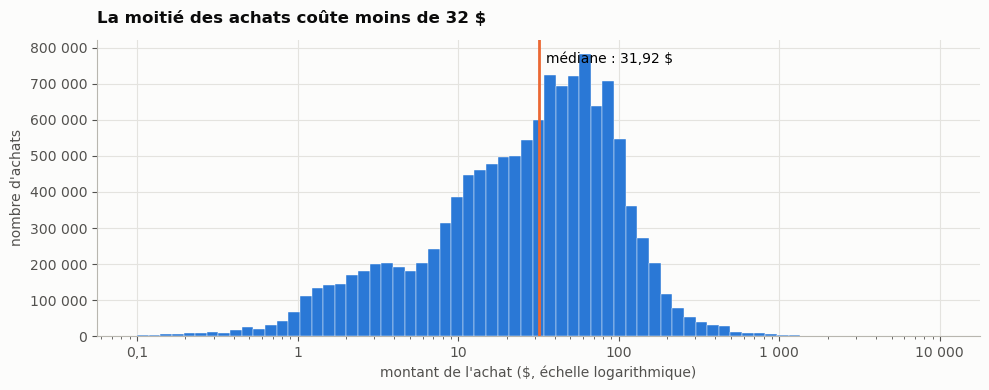

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.logspace(-1, 4, 70)
ax.hist(montants_achats, bins=bins, color=BLUE, edgecolor="white", linewidth=0.3)
ax.set_xscale("log")
mediane = montants_achats.median()
ax.axvline(mediane, color=ORANGE, linewidth=2)
ax.text(mediane * 1.1, ax.get_ylim()[1] * 0.92, f"médiane : {mediane:.2f} $".replace(".", ","), color="black")
ax.set_xlabel("montant de l'achat ($, échelle logarithmique)")
ax.set_ylabel("nombre d'achats")
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000])
ax.set_xticklabels(["0,1", "1", "10", "100", "1 000", "10 000"])
ax.set_title('La moitié des achats coûte moins de 32 $')
fig.tight_layout()
save_figure(fig, "P6-01_montants")
plt.show()

In [4]:
part = pd.DataFrame({
    "remboursements_%": rate_table(df, "mcc_family", "is_negative_amount")["taux_%"],
    "achats_sans_centimes_%": rate_table(df, "mcc_family", "is_round_amount")["taux_%"],
}).sort_values("remboursements_%", ascending=False)
print(f"Part des remboursements : {100 * df['is_negative_amount'].mean():.2f} % ; "
      f"part des achats sans centimes : {100 * df['is_round_amount'].mean():.2f} %")
part.round(2)

Part des remboursements : 4.96 % ; part des achats sans centimes : 10.15 %


,remboursements_%,achats_sans_centimes_%
mcc_family,,
Industrie et fabrication,28.36,28.83
Voyage et hébergement,27.45,27.92
Alimentation,9.13,9.92
"Transport, carburant et automobile",9.03,9.85
"Maison, jardin et électronique",1.42,2.41
Services publics et télécommunications,0.73,1.70
"Vêtements, beauté et services personnels",0.00,1.02
Grandes surfaces et commerces divers,0.00,0.99
Santé et soins,0.00,0.98


**Constats**

- Sur 13 305 915 transactions : 12 635 227 achats (montant positif), 660 049 remboursements (montant négatif) et 10 639 montants nuls.
- La moitié des achats coûte moins de 31,92 $. La moyenne (50,60 $) est plus haute que la médiane : quelques gros achats tirent la moyenne vers le haut.
- 1 % des achats coûte moins de 0,63 $ et 1 % plus de 324,52 $. Le quantile 99,9 % vaut 906,87 $ et le maximum 6 820,20 $. 9 185 achats dépassent 1 000 $.
- Le graphique montre que la plupart des achats se situent entre 10 et 100 $, avec un second groupe plus petit de quelques dollars.
- Les achats totalisent 639 354 565 $ et les remboursements -67 519 042 $ (remboursement médian : -79,00 $).
- Les remboursements (4,96 % des transactions) n'existent que dans six familles. Ils sont fréquents en industrie et fabrication (28,36 %) et en voyage et hébergement (27,45 %), et absents des six autres familles.
- Les achats sans centimes font 10,15 % des transactions, mais 80,57 % en services professionnels et financiers.

## P6-02 : analyser les canaux de paiement

Bande magnétique (Swipe), puce (Chip) et en ligne : répartition et évolution par année.

Critère de fin : graphique commenté. Voir `docs/P6-02_canaux_paiement.md`.

In [5]:
canaux = pd.crosstab(df["year"], df["canal"], normalize="index").mul(100)
canaux = canaux[["Bande magnétique", "Puce", "En ligne"]]
print(df["canal"].value_counts().to_string())
canaux.round(1)

Bande magnétique    6967185
Puce                4780818
En ligne            1557912


canal,Bande magnétique,Puce,En ligne
year,,,
2010,89.1,0.0,10.9
2011,89.2,0.0,10.8
2012,88.9,0.0,11.1
2013,88.4,0.0,11.6
2014,88.2,0.0,11.8
2015,16.9,70.8,12.2
2016,16.8,71.0,12.2
2017,16.8,71.2,12.1
2018,16.9,71.0,12.1


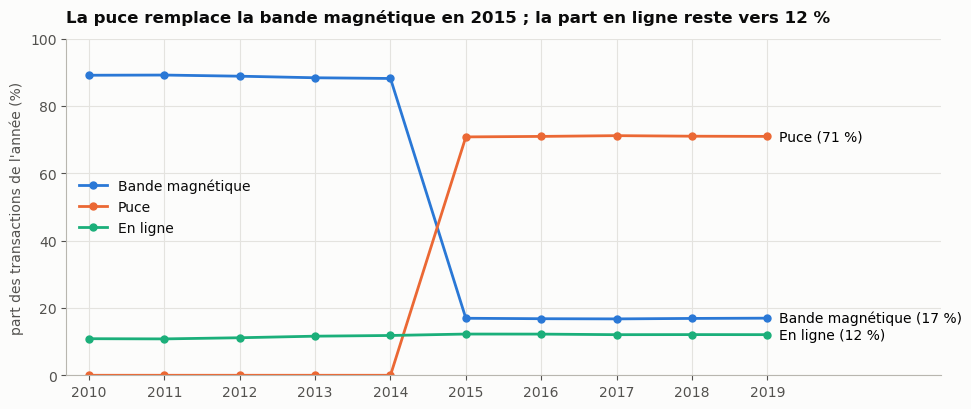

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for couleur, canal in zip(CATEGORIES, canaux.columns):
    ax.plot(canaux.index, canaux[canal], marker="o", markersize=5, color=couleur, label=canal)
    ax.text(canaux.index[-1] + 0.15, canaux[canal].iloc[-1], f"{canal} ({canaux[canal].iloc[-1]:.0f} %)",
            va="center", color="black")
ax.set_xticks(canaux.index)
ax.set_xlim(canaux.index[0] - 0.3, canaux.index[-1] + 2.3)
ax.set_ylim(0, 100)
ax.set_ylabel("part des transactions de l'année (%)")
ax.legend(loc="center left")
ax.set_title('La puce remplace la bande magnétique en 2015 ; la part en ligne reste vers 12 %')
fig.tight_layout()
save_figure(fig, "P6-02_canaux_paiement")
plt.show()

**Constats**

- Sur toute la période : 6 967 185 transactions par bande magnétique, 4 780 818 par puce et 1 557 912 en ligne.
- De 2010 à 2014, la puce n'existe pas dans les données (0,0 %) : la bande magnétique fait environ 89 % des transactions.
- En 2015, le changement est brutal : la puce passe à 70,8 % et la bande magnétique tombe à 16,9 %. Ces parts ne bougent presque plus jusqu'en 2019 (71,0 % et 17,0 %).
- La part en ligne monte lentement, de 10,9 % en 2010 à 12,1 % en 2019.

## P6-03 : analyser l'évolution dans le temps (Q6)

Volumes et montants par mois et par année, puis effets du jour de la semaine et de l'heure.

Critère de fin : graphiques commentés. Voir `docs/P6-03_evolution_temps.md`.

In [7]:
par_annee = df.groupby("year").agg(
    transactions=("id", "size"),
    achats_total=("achat", "sum"),
    clients_actifs=("client_id", "nunique"),
    cartes_actives=("card_id", "nunique"),
)
par_annee["achat_moyen"] = df[achats].groupby("year")["amount"].mean()
par_annee["transactions_par_client"] = par_annee["transactions"] / par_annee["clients_actifs"]
par_annee.round(1)

,transactions,achats_total,clients_actifs,cartes_actives,achat_moyen,transactions_par_client
year,,,,,,
2010,1240880,60822378.0,1137,2896,51.7,1091.4
2011,1290770,62464012.2,1167,3137,51.0,1106.1
2012,1321672,63576173.9,1177,3245,50.7,1122.9
2013,1352808,65186300.8,1190,3339,50.8,1136.8
2014,1365537,65450869.0,1195,3418,50.5,1142.7
2015,1388065,66503695.2,1204,3473,50.4,1152.9
2016,1392117,66831179.0,1210,3497,50.5,1150.5
2017,1399308,66681436.9,1209,3492,50.2,1157.4
2018,1394792,66522068.1,1208,3488,50.2,1154.6


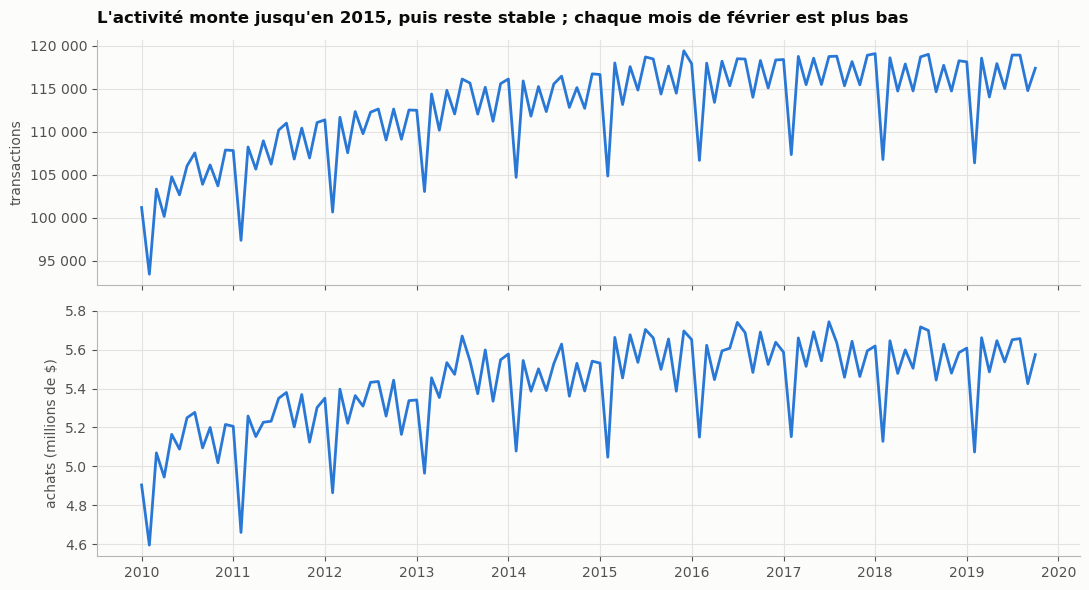

Mois le plus faible : 2010-02 93470
Mois le plus fort : 2015-12 119396
Transactions moyennes par mois de l'année :
month
1     113916
2     103135
3     114539
4     110618
5     114619
6     111852
7     115368
8     115687
9     111780
10    114864
11    111499
12    115406


In [8]:
mensuel = df.groupby(["year", "month"]).agg(transactions=("id", "size"), achats_total=("achat", "sum"))
mensuel.index = pd.to_datetime(dict(year=mensuel.index.get_level_values(0),
                                    month=mensuel.index.get_level_values(1), day=1))
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(mensuel.index, mensuel["transactions"], color=BLUE)
axes[0].set_ylabel("transactions")
axes[0].yaxis.set_major_formatter(THOUSANDS)
axes[1].plot(mensuel.index, mensuel["achats_total"] / 1e6, color=BLUE)
axes[1].set_ylabel("achats (millions de $)")
axes[0].set_title("L'activité monte jusqu'en 2015, puis reste stable ; chaque mois de février est plus bas")
fig.tight_layout()
save_figure(fig, "P6-03_evolution_mensuelle")
plt.show()
print("Mois le plus faible :", mensuel["transactions"].idxmin().strftime("%Y-%m"), int(mensuel["transactions"].min()))
print("Mois le plus fort :", mensuel["transactions"].idxmax().strftime("%Y-%m"), int(mensuel["transactions"].max()))
moyenne_mois = df.groupby("month")["id"].size() / df.groupby("month")["year"].nunique()
print("Transactions moyennes par mois de l'année :")
print(moyenne_mois.round(0).astype(int).to_string())

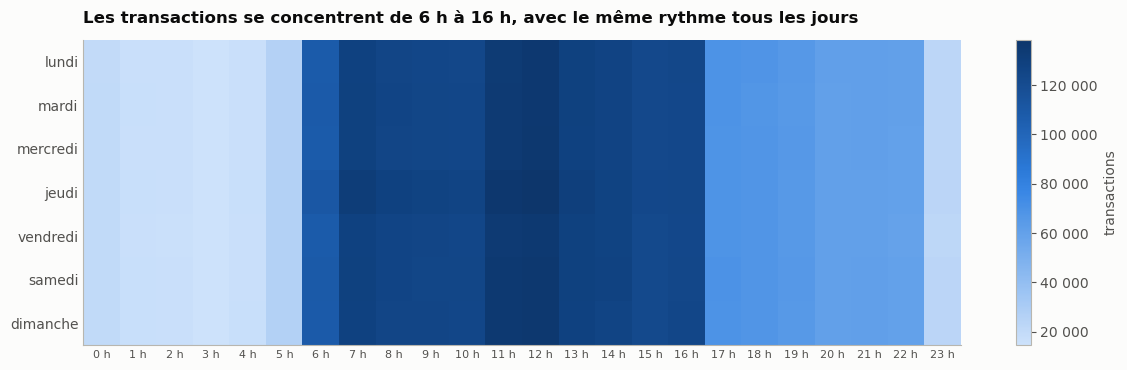

Transactions par jour :
lundi       1896914
mardi       1897678
mercredi    1895871
jeudi       1918666
vendredi    1895372
samedi      1902370
dimanche    1899044
Heure la plus chargée : 12 h (953,498) ; la plus calme : 3 h (103,478)
Part des transactions de nuit (0 h à 5 h 59) : 5.8 %


In [9]:
chaleur = df.groupby(["weekday", "hour"]).size().unstack()
fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(chaleur, cmap=sequential_cmap(), aspect="auto")
ax.set_yticks(range(7))
ax.set_yticklabels(JOURS)
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h} h" for h in range(24)], fontsize=8)
ax.grid(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, label="transactions", format=THOUSANDS)
ax.set_title('Les transactions se concentrent de 6 h à 16 h, avec le même rythme tous les jours')
fig.tight_layout()
save_figure(fig, "P6-03_jour_heure")
plt.show()
par_jour = df.groupby("weekday").size()
par_jour.index = JOURS
par_heure = df.groupby("hour").size()
print("Transactions par jour :")
print(par_jour.to_string())
print(f"Heure la plus chargée : {par_heure.idxmax()} h ({par_heure.max():,}) ; "
      f"la plus calme : {par_heure.idxmin()} h ({par_heure.min():,})")
print(f"Part des transactions de nuit (0 h à 5 h 59) : {100 * df['is_night'].mean():.1f} %")

**Constats**

- Le nombre de transactions monte de 1 240 880 en 2010 à 1 399 308 en 2017, puis reste stable. 2019 compte 1 159 966 transactions, car les données s'arrêtent en octobre.
- Les clients actifs passent de 1 137 en 2010 à 1 210 en 2016, et les cartes actives de 2 896 à 3 497. L'achat moyen baisse un peu, de 51,7 $ à 50,2 $.
- Le mois le plus faible est février 2010 (93 470 transactions) et le plus fort décembre 2015 (119 396). Février est chaque année le mois le plus bas (103 135 en moyenne) : il compte moins de jours.
- Le jour de la semaine ne change presque rien : de 1 895 372 transactions le vendredi à 1 918 666 le jeudi.
- L'heure compte beaucoup : la plus chargée est 12 h (953 498 transactions) et la plus calme 3 h (103 478). La carte de chaleur montre une forte activité de 6 h à 16 h, avec le même rythme tous les jours.
- 5,8 % des transactions ont lieu la nuit (de 0 h à 5 h 59).